# Imports

In [1]:
import kagglehub
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from data.data_loader import load_blood_cells
from methods.bcgd_gauss_southwell import gs_bcgd
from methods.bcgd_randomized import randomized_bcgd
from methods.gradient_descent import gradient_descent
from methods.utils.accuracy import accuracy
from methods.utils.block_size import block_step_size, full_step_size
from methods.utils.gradient import MultiLogisticRegressionOracle, CachedMultiLogisticRegressionOracle
from methods.utils.results import accuracy_vs_CPU, distance_vs_iterations

rng = np.random.default_rng(seed=42) # Turnoff or modify if no seeding will be used.
MAX_ITER = 3000

/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1777400150.368713   26901 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1777400150.476939   26901 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1777400154.017827   26901 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Data Loading

## Synthetic Data

In [2]:
n_categories = 50
n_features = 1000
n_examples = 1000

syntetic_features = rng.random((n_examples, n_features))
X = rng.random((n_features, n_categories))
E = rng.random((n_examples, n_categories))

transformation = np.dot(syntetic_features,X) + E
syntetic_labels = np.argmax(transformation, axis= 1)

syntetic_test_features = rng.random((n_examples, n_features))
test_transformation = np.dot(syntetic_features,X) + E
syntetic_test_labels = np.argmax(test_transformation, axis= 1)

syntetic_data = {
    "n_categories": n_categories,
    "n_features": n_features,
    "train_features": syntetic_features,
    "train_labels": syntetic_labels,
    "test_features": syntetic_test_features,
    "test_labels": syntetic_test_labels,
    "tolerance": 1e-4,
}

## MNIST Dataset

In [2]:
n_components = 50
(mnist_features, mnist_labels), (mnist_features_test, mnist_labels_test) = mnist.load_data()

mnist_features = mnist_features.reshape((mnist_features.shape[0],-1))
mnist_features_test = mnist_features_test.reshape((mnist_features_test.shape[0],-1))

scaler = StandardScaler()
pca = PCA(n_components=n_components)

mnist_reduced_features = scaler.fit_transform(mnist_features)
mnist_reduced_features = pca.fit_transform(mnist_reduced_features)

mnist_reduced_features_test = scaler.transform(mnist_features_test)
mnist_reduced_features_test = pca.transform(mnist_reduced_features_test)

mnist_data = {
    "n_categories": 10,
    "n_features": n_components,
    "train_features": mnist_reduced_features,
    "train_labels": mnist_labels,
    "test_features": mnist_reduced_features_test,
    "test_labels": mnist_labels_test,
    "tolerance": 1e-4,
}

## Bloodcell Dataset

In [ ]:
# run this cell only once to download the dataset, then comment it out
# path = kagglehub.dataset_download("unclesamulus/blood-cells-image-dataset", output_dir="blood_cells_data")

100%|██████████| 268M/268M [00:26<00:00, 10.6MB/s] 

Extracting files...


In [3]:
blood_features, blood_labels, labels_names = load_blood_cells(dataset_dir=f"data_blood_cells_data/bloodcells_dataset")
blood_train_features, blood_test_features, blood_train_labels, blood_test_labels = train_test_split(blood_features, blood_labels, test_size=0.2, random_state=42)

In [4]:
n_components = 50

blood_train_features = blood_train_features.reshape((blood_train_features.shape[0],-1))
blood_test_features = blood_test_features.reshape((blood_test_features.shape[0],-1))

scaler_blood = StandardScaler()
pca_blood = PCA(n_components=n_components)

mnist_reduced_features = scaler_blood.fit_transform(blood_train_features)
mnist_reduced_features = pca_blood.fit_transform(blood_test_features)

blood_data = {
    "n_categories": len(labels_names),
    "n_features": blood_train_features.shape[1],
    "train_features": blood_train_features,
    "train_labels": blood_train_labels,
    "test_features": blood_test_features,
    "test_labels": blood_test_labels,
    "tolerance": 1e-4,
}

# Method Calls
This section is for implementing all the methods that will be used for generating graphs or any other types of solutions

In [5]:
dataset_name = "Blood"
active_data = blood_data

#calculated step sizes
step_sizes = block_step_size(active_data["train_features"])
gd_step_size = full_step_size(active_data["train_features"])

oracle = MultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])
cached_oracle = CachedMultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])

## Gradient Descent

In [6]:
gradient_descent_results = gradient_descent(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    gd_step_size,
    tol=active_data["tolerance"],
    debug=True,
    max_iter=MAX_ITER,
)

Iteration 0: Loss = 27652.50843410475, sequential distance: 0.010706736075562802, Accuracy = 0.19600672858919038
Iteration 500: Loss = 21556.006351689884, sequential distance: 0.0008226276317962276, Accuracy = 0.49425875813647335
Iteration 1000: Loss = 19417.919915884493, sequential distance: 0.0005887105583021849, Accuracy = 0.5268046515029621
Iteration 1500: Loss = 18172.278358259624, sequential distance: 0.00047516035637278396, Accuracy = 0.5711987127916331
Iteration 2000: Loss = 17314.004047668623, sequential distance: 0.00040458558457134766, Accuracy = 0.5962115117384627
Iteration 2500: Loss = 16671.7650377444, sequential distance: 0.0003551996732308007, Accuracy = 0.6102537848314196


In [7]:
gradient_descent_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gradient_descent_results["history"]
]
gradient_descent_results["test_accuracy"] = accuracy(active_data["test_features"],active_data["test_labels"], gradient_descent_results["x_k"])

In [8]:
np.save("gd_ac.npy", gradient_descent_results["accuracies"])
np.save("gd_test_ac.npy", gradient_descent_results["test_accuracy"])
np.save("gd_times.npy", gradient_descent_results["times"])

## BCGD Randomized

In [9]:
randomized_bcgd_results = randomized_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    step_sizes,
    tol=active_data["tolerance"],
    debug=True,
    max_iter=MAX_ITER,
)

iteration: 0, sequential distance: 0.6525622590744506, loss: 27683.21740780798
accuracy: 0.19600672858919038
iteration: 500, sequential distance: 0.017921069140269513, loss: 19424.521447510986
accuracy: 0.5598625027426315
iteration: 1000, sequential distance: 0.010357432729323806, loss: 16744.640337180797
accuracy: 0.6317560155050099
iteration: 1500, sequential distance: 0.009731867340893305, loss: 15573.566245307484
accuracy: 0.6457982885979668
iteration: 2000, sequential distance: 0.007199911797775455, loss: 14940.89239031526
accuracy: 0.6555986250274263
iteration: 2500, sequential distance: 0.006070994167804657, loss: 14369.281712334254
accuracy: 0.6640824983544211


In [10]:
randomized_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in randomized_bcgd_results["history"]
]

randomized_bcgd_results["test_accuracy"] = accuracy(active_data["test_features"],active_data["test_labels"], randomized_bcgd_results["x_k"])

In [12]:
np.save("rd_ac.npy", randomized_bcgd_results["accuracies"])
np.save("rd_test_ac.npy", randomized_bcgd_results["test_accuracy"])
np.save("rd_times.npy", randomized_bcgd_results["times"])

## Gauss-Southwell BCGD

In [11]:
gs_bcgd_results = gs_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    cached_oracle,
    step_sizes,
    tol=active_data["tolerance"],
    debug=True,
    max_iter=MAX_ITER,
)

iteration: 0, selected_block: 1120, sequential distance: 0.670554681763506, loss: 27595.758709
accuracy: 19.60%
iteration: 500, selected_block: 319, sequential distance: 0.0346823772933536, loss: 14790.039700
accuracy: 65.38%
iteration: 1000, selected_block: 2024, sequential distance: 0.04795341965230398, loss: 13528.575964
accuracy: 67.18%
iteration: 1500, selected_block: 639, sequential distance: 0.016332871338409233, loss: 12953.313962
accuracy: 68.14%
iteration: 2000, selected_block: 1076, sequential distance: 0.01712767559883963, loss: 12611.831846
accuracy: 68.91%
iteration: 2500, selected_block: 2588, sequential distance: 0.024229103328510034, loss: 12375.793649
accuracy: 69.41%


In [13]:
gs_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gs_bcgd_results["history"]
]

gs_bcgd_results["test_accuracy"] = accuracy(active_data["test_features"],active_data["test_labels"], gs_bcgd_results["x_k"])

In [14]:
np.save("gs_ac.npy", gs_bcgd_results["accuracies"])
np.save("gs_test_ac.npy", gs_bcgd_results["test_accuracy"])
np.save("gs_times.npy", gs_bcgd_results["times"])

# Results

## Accuracy vs CPU Time

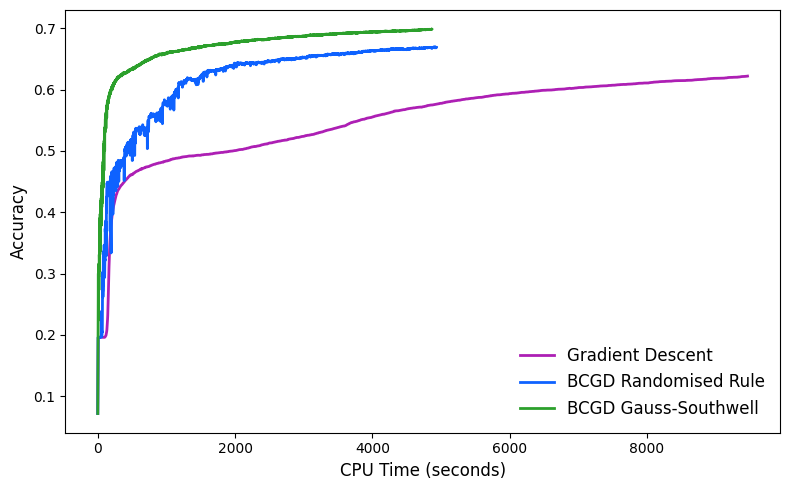

In [15]:
plotting_data = {
    "Gradient Descent": (gradient_descent_results["times"], gradient_descent_results["accuracies"]),
    "BCGD Randomised Rule": (randomized_bcgd_results["times"], randomized_bcgd_results["accuracies"]),
    "BCGD Gauss-Southwell": (gs_bcgd_results["times"], gs_bcgd_results["accuracies"]),
}

accuracy_vs_CPU(plotting_data)

## Tabular Performance

In [16]:
print(f"====== Results for {dataset_name} ========")
print(f"---- Gradient Descent ----")
print(f"Final Iteration: {gradient_descent_results['iterations']}")
print(f"Final Training Accuracy: {gradient_descent_results['accuracies'][-1]}")
print(f"Testing Accuracy: {gradient_descent_results['test_accuracy']}")
print(f"Total CPU time: {gradient_descent_results['times'][-1]} seconds")

print(f"---- Randomized BCGD ----")
print(f"Final Iteration: {randomized_bcgd_results['iterations']}")
print(f"Final Training Accuracy: {randomized_bcgd_results['accuracies'][-1]}")
print(f"Testing Accuracy: {randomized_bcgd_results['test_accuracy']}")
print(f"Total CPU time: {randomized_bcgd_results['times'][-1]} seconds")

print(f"---- GS BCGD ----")
print(f"Final Iteration: {gs_bcgd_results['iterations']}")
print(f"Final Training Accuracy: {gs_bcgd_results['accuracies'][-1]}")
print(f"Testing Accuracy: {gs_bcgd_results['test_accuracy']}")
print(f"Total CPU time: {gs_bcgd_results['times'][-1]} seconds")

====== Results for Blood ========
---- Gradient Descent ----
Final Iteration: 2999
Final Training Accuracy: 0.6221750895926278
Testing Accuracy: 0.610412401286926
Total CPU time: 9464.404984110999 seconds
---- Randomized BCGD ----
Final Iteration: 2999
Final Training Accuracy: 0.6690558034081767
Testing Accuracy: 0.6651067563615092
Total CPU time: 4931.965877557999 seconds
---- GS BCGD ----
Final Iteration: 2999
Final Training Accuracy: 0.6986762232136327
Testing Accuracy: 0.6844106463878327
Total CPU time: 4865.880753564001 seconds


## Distance vs. Iterations

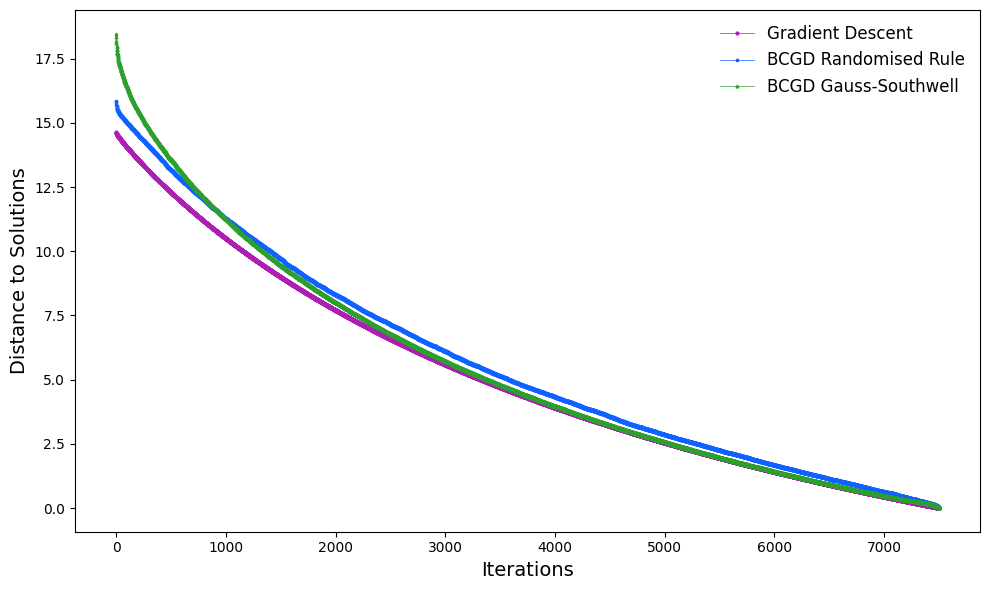

In [16]:
distance_plot_data = {
    "Gradient Descent": [np.linalg.norm(x - gradient_descent_results["history"][-1])  for x in gradient_descent_results["history"]],
    "BCGD Randomised Rule": [np.linalg.norm(x - randomized_bcgd_results["history"][-1])  for x in randomized_bcgd_results["history"]],
    "BCGD Gauss-Southwell": [np.linalg.norm(x - gs_bcgd_results["history"][-1])  for x in gs_bcgd_results["history"]],
}

distance_to_theoretical_plot_data = {
    "Gradient Descent": [np.linalg.norm(x - X)  for x in gradient_descent_results["history"]],
    "BCGD Randomised Rule": [np.linalg.norm(x - X)  for x in randomized_bcgd_results["history"]],
    "BCGD Gauss-Southwell": [np.linalg.norm(x - X)  for x in gs_bcgd_results["history"]],
}

distance_vs_iterations(distance_plot_data) 

## Algorithm Weardown

In [13]:
def wear_down_algorithm(data, oracle, method, min_step_size, max_step_size, tol, max_iter, step_to_interval = False):
    x_k = np.zeros((data["n_features"], data["n_categories"]))
    results =[]
    step_sizes = np.exp(np.linspace(np.log(min_step_size), np.log(max_step_size), 20))
    
    for step_size in step_sizes:
        print(step_size)
        if step_to_interval:
            step_size = [step_size]*data["n_features"]
        algorithm_results = method(
            x_k,
            oracle,
            step_size,
            tol=tol,
            max_iter=max_iter,
        )
        history = np.array(algorithm_results["history"])
        if np.isnan(history).any():
            break
        else:
            results.append(algorithm_results["iterations"])
    return results

In [37]:
import matplotlib.pyplot as plt

def plot_weardown(data, min_step_size, max_step_size):
    step_sizes = np.exp(np.linspace(np.log(min_step_size), np.log(max_step_size), 20))
    colors = ["#ad1fb4", "#0e62ff", "#2ca02c"] 
    fig, ax = plt.subplots(figsize=(8, 5))

    markers = ['o', 's', '^']
    linewidth = 1.5
    markersize = 2

    for i, (label, (iterations)) in enumerate(data.items()):
        ax.plot(
            step_sizes[:len(iterations)],
            iterations,
            marker=markers[i % len(markers)],
            color=colors[i],
            linewidth=linewidth,
            markersize=markersize,
            label=label
        )

    ax.set_xlabel("Step Size", fontsize=14)
    ax.set_ylabel("Iterations", fontsize=14)
    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.grid(False)
    
    ax.tick_params(colors='black')

    ax.legend(frameon=False, fontsize=12)

    plt.tight_layout()
    plt.show()

In [41]:
gs_bcgd_weardown_results = wear_down_algorithm(active_data, cached_oracle, gs_bcgd, 0.001, 10, 1, 10000, step_to_interval=True)

wear_down_plot_data = {
    "Gradient Descent": gradient_descent_weardown_results,
    "BCGD Randomised Rule": randomized_bcgd_weardown_results,
    "BCGD Gauss-Southwell": gs_bcgd_weardown_results,
}

0.0010000000000000002


In [ ]:
gs_bcgd_weardown_results = wear_down_algorithm(active_data, cached_oracle, gs_bcgd, 0.001, 10, 1, 10000, step_to_interval=True)
gradient_descent_weardown_results = wear_down_algorithm(active_data, oracle, gradient_descent, 0.001, 10, 1, 10000)
randomized_bcgd_weardown_results = wear_down_algorithm(active_data, oracle, randomized_bcgd, 0.001, 10, 1, 10000, step_to_interval=True)

wear_down_plot_data = {
    "Gradient Descent": gradient_descent_weardown_results,
    "BCGD Randomised Rule": randomized_bcgd_weardown_results,
    "BCGD Gauss-Southwell": gs_bcgd_weardown_results,
}

0.0010000000000000002
0.0016237767391887226
0.0026366508987303605
0.004281332398719395
0.006951927961775609
0.011288378916846899
0.01832980710832437
0.029763514416313194
0.04832930238571757
0.0784759970351462
0.12742749857031355
0.2069138081114791
0.3359818286283785
0.5455594781168526
0.8858667904100832
1.4384498882876642
2.335721469090125
3.7926901907322517
6.158482110660274
10.000000000000002


/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/methods/utils/gradient.py:51: RuntimeWarning: overflow encountered in exp
  exp_S = np.exp(self.S)
/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/methods/utils/gradient.py:53: RuntimeWarning: invalid value encountered in divide
  softmax_entries = exp_S / summed_entries


0.0010000000000000002
0.0016237767391887226
0.0026366508987303605
0.004281332398719395
0.006951927961775609
0.011288378916846899
0.01832980710832437
0.029763514416313194
0.04832930238571757
0.0784759970351462
0.12742749857031355


/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/methods/utils/gradient.py:28: RuntimeWarning: overflow encountered in exp
  transformed_entries = np.exp(np.dot(self.predictors, x)) # m x k
/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/methods/utils/gradient.py:30: RuntimeWarning: invalid value encountered in divide
  softmax_entries = transformed_entries / summed_entries # m x k


0.0010000000000000002
0.0016237767391887226
0.0026366508987303605
0.004281332398719395
0.006951927961775609
0.011288378916846899
0.01832980710832437
0.029763514416313194
0.04832930238571757
0.0784759970351462
0.12742749857031355
0.2069138081114791
0.3359818286283785
0.5455594781168526
0.8858667904100832
1.4384498882876642
2.335721469090125
3.7926901907322517
6.158482110660274


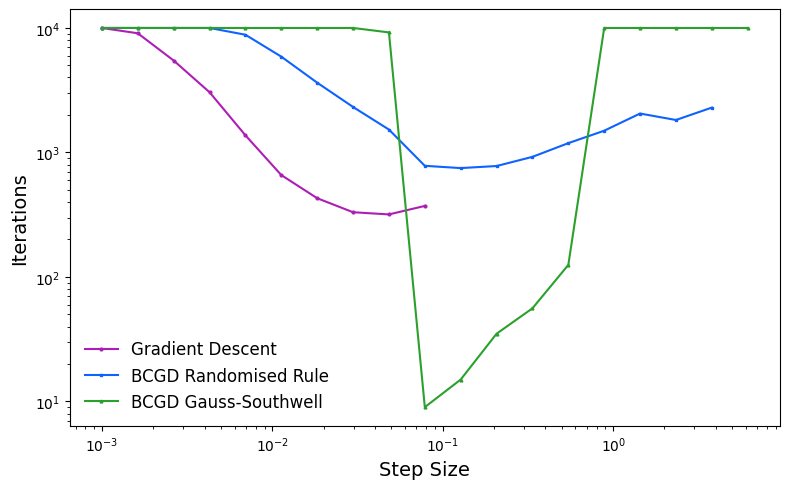

In [47]:
plot_weardown(wear_down_plot_data, 0.001, 10)

In [28]:
step_sizes

array([0.02375133, 0.02426334, 0.02341544, 0.02485785, 0.02491737,
       0.02425436, 0.02407753, 0.02349108, 0.02455056, 0.0236524 ,
       0.02403848, 0.02283967, 0.02389167, 0.0226663 , 0.0245319 ,
       0.02320578, 0.02412605, 0.02340739, 0.02386991, 0.02511882,
       0.02353644, 0.02397794, 0.02282129, 0.02358171, 0.02416061,
       0.02338517, 0.0244293 , 0.02549038, 0.02225487, 0.02400879,
       0.02238388, 0.02442187, 0.02307237, 0.02404053, 0.02250298,
       0.02386433, 0.02271594, 0.02503645, 0.02492821, 0.02376362,
       0.02267594, 0.02343645, 0.02482311, 0.02510079, 0.02390148,
       0.02468106, 0.02441266, 0.0233394 , 0.02419628, 0.02491215,
       0.02468114, 0.02311356, 0.02511546, 0.02460729, 0.024839  ,
       0.02501825, 0.02517971, 0.02336393, 0.02382963, 0.02376684,
       0.02279914, 0.02506289, 0.02379992, 0.0238674 , 0.02508727,
       0.02346105, 0.02473848, 0.02526294, 0.02553046, 0.02351968,
       0.02368859, 0.02459871, 0.02322418, 0.02400526, 0.02384